# Interest Rate Models: Hull-White, Caps and Swaptions

**Goal.** Price interest rate options consistently with today's curve. The Hull-White
model is the workhorse of rates desks and of XVA and ALM engines: it fits the curve
exactly, has closed forms for caps and swaptions, and is easy to simulate.

$$dr_t = \big(\theta(t) - a\,r_t\big)\,dt + \sigma\,dW_t$$

- $\theta(t)$ is chosen so that model bond prices equal market discount factors.
- $a$ (mean reversion) controls how volatility decays along the curve.
- $\sigma$ is a **normal** volatility (in bp per year), the market convention since rates
  went negative in 2014-2022.

**Plan.** 1. Fit the curve and simulate · 2. Caps: market quotes and calibration ·
3. Swaptions by Jamshidian · 4. What mean reversion does.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("hullwhite.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/09-interest-rate-models")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hullwhite import (InitialCurve, HullWhite, market_cap_price, atm_cap_strike, implied_cap_normal_vol,
                       calibrate, implied_swaption_normal_vol)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"
curve = InitialCurve()

## 1. Fitting today's curve and simulating the short rate

The short rate is simulated **exactly** as $r_t = x_t + \alpha(t)$, where $x$ is an
Ornstein-Uhlenbeck process started at 0 and $\alpha(t)$ is built from today's forward
curve. The Monte Carlo discount factors $\mathbb{E}[e^{-\int_0^T r_s ds}]$ must then
reproduce the market curve, within the Monte Carlo standard error.

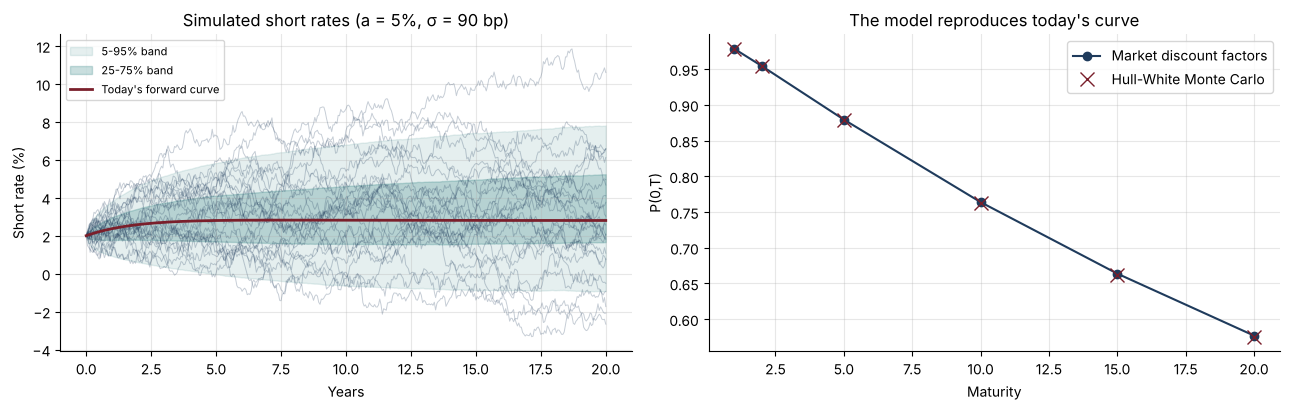

,1Y,2Y,5Y,10Y,15Y,20Y
Market,0.97822,0.95418,0.87928,0.76380,0.66373,0.57696
Monte Carlo,0.97825,0.95420,0.87897,0.76288,0.66228,0.57545
Error (bp of price),0.28191,0.15619,-3.10061,-9.16528,-14.55657,-15.15384
MC std error (bp),0.22325,0.60621,2.09535,4.69873,6.95206,8.71641


In [2]:
hw = HullWhite(a=0.05, sigma=0.009, curve=curve)
t, r, disc = hw.simulate(20.0, 400, 50_000, seed=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for i in range(25):
    axes[0].plot(t, r[i] * 100, color=NAVY, alpha=0.25, lw=0.7)
for lo, hi, a in [(5, 95, 0.12), (25, 75, 0.25)]:
    axes[0].fill_between(t, np.percentile(r, lo, axis=0) * 100, np.percentile(r, hi, axis=0) * 100, color=TEAL, alpha=a,
                         label=f"{lo}-{hi}% band")
axes[0].plot(t, curve.inst_forward(t) * 100, color=BORDEAUX, lw=2, label="Today's forward curve")
axes[0].set(xlabel="Years", ylabel="Short rate (%)", title="Simulated short rates (a = 5%, σ = 90 bp)"); axes[0].legend(fontsize=8)

check_T = np.array([1, 2, 5, 10, 15, 20])
cols = [int(T / 20 * 400) for T in check_T]
mc_df = np.array([disc[:, c].mean() for c in cols])
mc_se = np.array([disc[:, c].std() / np.sqrt(disc.shape[0]) for c in cols])
axes[1].plot(check_T, curve.df(check_T), "o-", color=NAVY, label="Market discount factors")
axes[1].plot(check_T, mc_df, "x", color=BORDEAUX, ms=10, label="Hull-White Monte Carlo")
axes[1].set(xlabel="Maturity", ylabel="P(0,T)", title="The model reproduces today's curve"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/short_rate.png", dpi=150); plt.show()
pd.DataFrame({"Market": curve.df(check_T), "Monte Carlo": mc_df, "Error (bp of price)": (mc_df - curve.df(check_T)) * 1e4,
              "MC std error (bp)": mc_se * 1e4},
             index=[f"{T}Y" for T in check_T]).round(5).T

## 2. Caps: from market normal volatilities to a calibrated model

A **caplet** pays $\delta\,(L(T, T+\delta) - K)^+$: a call on a future Libor/Euribor
rate. In Hull-White it is exactly a put on a zero-coupon bond:

$$\text{Caplet} = (1 + K\delta)\;\text{ZBP}\big(T,\ T+\delta,\ 1/(1+K\delta)\big)$$

The market quotes at-the-money caps in Bachelier normal vols. We convert the quotes to
prices and fit $(a, \sigma)$.

Calibrated a = 0.0089, sigma = 89.9 bp, RMSE on prices = 3.92%


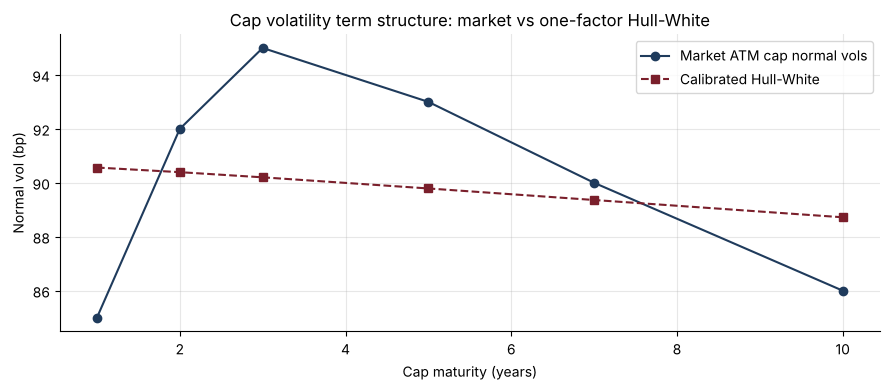

,ATM strike (%),Market vol (bp),Model vol (bp)
1Y,2.31,85.0,90.57
2Y,2.44,92.0,90.39
3Y,2.53,95.0,90.20
5Y,2.64,93.0,89.79
7Y,2.69,90.0,89.36
10Y,2.73,86.0,88.72


In [3]:
mats = np.array([1, 2, 3, 5, 7, 10])
market_vols = np.array([0.0085, 0.0092, 0.0095, 0.0093, 0.0090, 0.0086])      # in rate units: 85 bp = 0.0085
fitted, rmse = calibrate(curve, mats, market_vols)
model_vols = [implied_cap_normal_vol(curve, T, atm_cap_strike(curve, T), fitted.cap(T, atm_cap_strike(curve, T))) for T in mats]
print(f"Calibrated a = {fitted.a:.4f}, sigma = {fitted.sigma * 1e4:.1f} bp, RMSE on prices = {rmse:.2%}")

plt.figure(figsize=(9, 4))
plt.plot(mats, market_vols * 1e4, "o-", color=NAVY, label="Market ATM cap normal vols")
plt.plot(mats, np.array(model_vols) * 1e4, "s--", color=BORDEAUX, label="Calibrated Hull-White")
plt.xlabel("Cap maturity (years)"); plt.ylabel("Normal vol (bp)"); plt.legend()
plt.title("Cap volatility term structure: market vs one-factor Hull-White")
plt.tight_layout(); plt.savefig("images/cap_calibration.png", dpi=150); plt.show()
pd.DataFrame({"ATM strike (%)": [atm_cap_strike(curve, T) * 100 for T in mats], "Market vol (bp)": market_vols * 1e4,
              "Model vol (bp)": np.array(model_vols) * 1e4}, index=[f"{T}Y" for T in mats]).round(2)

**Reading the result.** With a constant $\sigma$ and positive mean reversion, Hull-White
can only produce **decreasing** cap vols. The market shows a **hump** around 3 years, so the
fit is a compromise. This is a well-known limitation and the reason desks use a
time-dependent $\sigma(t)$ (piecewise constant, fitted to each cap) or a two-factor model.

## 3. Swaptions by Jamshidian's decomposition

A payer swaption is a put on a coupon bond. Because all bond prices in Hull-White are
decreasing functions of the same $r$, the put on the coupon bond splits into a sum of
puts on zero-coupon bonds (Jamshidian, 1989), each with a closed form. Below, the model
swaption prices are expressed as normal vols, the way the market quotes them.

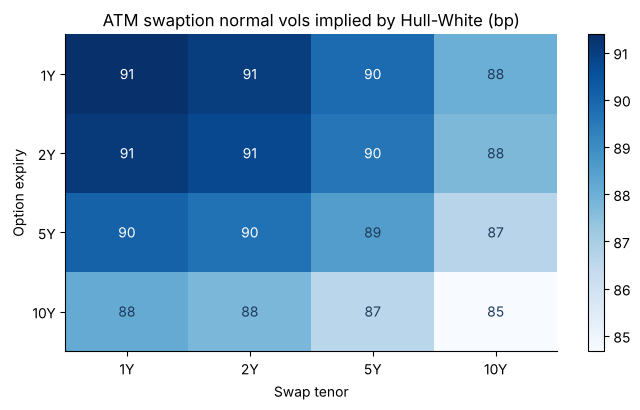

In [4]:
expiries, tenors = [1, 2, 5, 10], [1, 2, 5, 10]
grid = pd.DataFrame(index=[f"{e}Y" for e in expiries], columns=[f"{n}Y" for n in tenors], dtype=float)
for e in expiries:
    for n in tenors:
        pay = e + np.arange(1, n + 1)
        F = (curve.df(e) - curve.df(pay[-1])) / curve.df(pay).sum()
        price = fitted.payer_swaption(e, n, F)
        grid.loc[f"{e}Y", f"{n}Y"] = implied_swaption_normal_vol(curve, e, n, price)[0] * 1e4

fig, ax = plt.subplots(figsize=(7, 4.2))
im = ax.imshow(grid.values.astype(float), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(tenors)), grid.columns); ax.set_yticks(range(len(expiries)), grid.index)
for i in range(len(expiries)):
    for j in range(len(tenors)):
        ax.text(j, i, f"{grid.values[i, j]:.0f}", ha="center", va="center", color="white" if grid.values[i, j] > grid.values.mean() else NAVY)
ax.set(xlabel="Swap tenor", ylabel="Option expiry", title="ATM swaption normal vols implied by Hull-White (bp)")
ax.grid(False); plt.colorbar(im); plt.tight_layout(); plt.savefig("images/swaption_grid.png", dpi=150); plt.show()

Vols fall with both expiry and tenor: mean reversion damps the volatility of rates far in
the future and of long-dated swap rates, which average many forward rates.

## 4. What mean reversion does

With $\sigma$ fixed, a higher $a$ pulls rates back to the curve faster, so longer caps
become relatively cheaper. Mean reversion is the lever that shapes the vol term structure.

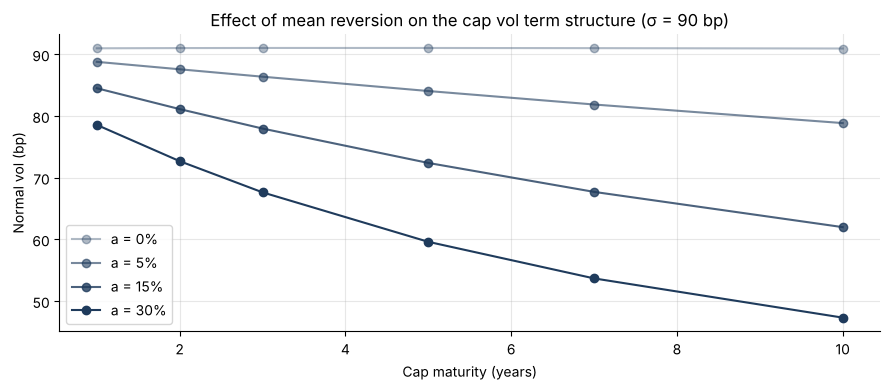

In [5]:
plt.figure(figsize=(9, 4))
for a_, alpha in [(0.001, 0.35), (0.05, 0.6), (0.15, 0.8), (0.30, 1.0)]:
    m = HullWhite(a_, 0.009, curve)
    vols = [implied_cap_normal_vol(curve, T, atm_cap_strike(curve, T), m.cap(T, atm_cap_strike(curve, T))) * 1e4 for T in mats]
    plt.plot(mats, vols, "o-", color=NAVY, alpha=alpha, label=f"a = {a_:.0%}")
plt.xlabel("Cap maturity (years)"); plt.ylabel("Normal vol (bp)"); plt.legend()
plt.title("Effect of mean reversion on the cap vol term structure (σ = 90 bp)")
plt.tight_layout(); plt.savefig("images/mean_reversion.png", dpi=150); plt.show()

## Conclusions
- Hull-White reproduces today's curve exactly, and its closed-form caplets and Jamshidian
  swaptions match Monte Carlo within the error bars (`test_hullwhite.py`).
- Calibrated to market cap vols, the one-factor model misses the 3-year hump: a concrete
  reason for time-dependent volatility or a second factor.
- **Next steps:** piecewise-constant σ(t), the two-factor G2++ model, Bermudan swaptions
  on a trinomial tree, and exposure simulation for CVA (project 15).